In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Carrega a planilha de alunos
dados = pd.read_csv('student_dataset_10000_rows.csv')

# 📄 Mostra as primeiras 5 linhas da tabela na tela
print("--- AMOSTRA DOS DADOS ORIGINAIS ---")
display(dados.head())

# 2. Divide os dados nas proporções do professor (70/20/10)
treino, resto = train_test_split(dados, test_size=0.30, random_state=42)
teste, validacao = train_test_split(resto, test_size=1/3, random_state=42)

# 3. Separa as colunas de comportamento (X) e a nota final (y)
colunas_perguntas = ['study_hours', 'attendance', 'sleep_hours', 'internet_usage', 'assignments_completed', 'previous_score']

X_treino = treino[colunas_perguntas]
y_treino = treino['exam_score']
X_teste = teste[colunas_perguntas]
y_teste = teste['exam_score']
X_validacao = validacao[colunas_perguntas]
y_validacao = validacao['exam_score']

# 4. NORMALIZAÇÃO DIRETA (Coloca tudo na mesma escala desde o início)
scaler = StandardScaler()
X_treino_norm = scaler.fit_transform(X_treino)
X_teste_norm = scaler.transform(X_teste)
X_validacao_norm = scaler.transform(X_validacao)

print("\n--- PASSO 1: DADOS PREPARADOS E NORMALIZADOS ---")


--- AMOSTRA DOS DADOS ORIGINAIS ---


,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed



--- PASSO 1: DADOS PREPARADOS E NORMALIZADOS ---


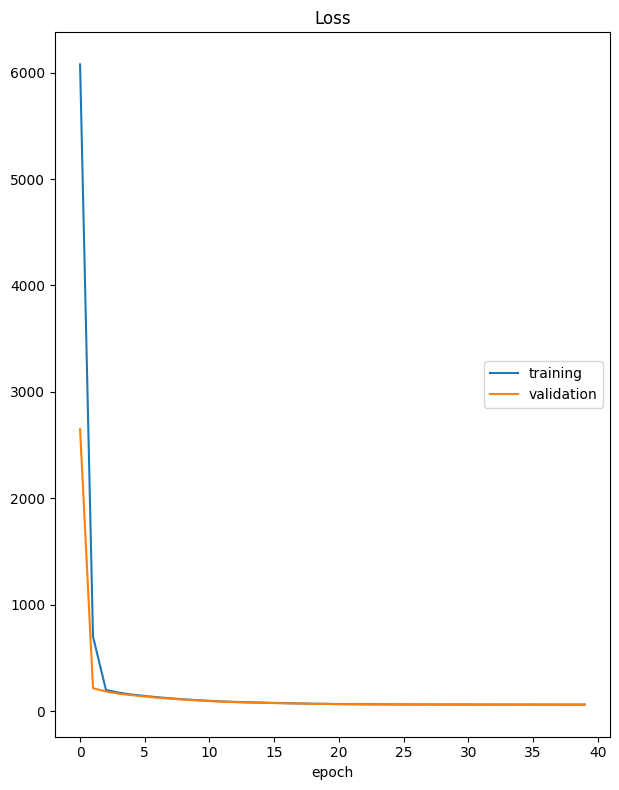

Loss
	training         	 (min:   60.274, max: 6078.361, cur:   60.296)
	validation       	 (min:   59.364, max: 2650.574, cur:   59.611)

--- TREINAMENTO CONCLUÍDO COM SUCESSO ---


In [ ]:
# 1. Garante a instalação da biblioteca de gráficos em tempo real
!pip install livelossplot --quiet

import tensorflow as tf
from tensorflow.keras import layers, models
from livelossplot import PlotLossesKeras

# 2. Configurando a estrutura da Inteligência Artificial
modelo_final = models.Sequential([
    layers.Dense(32, activation='relu', input_shape=(6,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1)
])

# 3. Compilando o modelo (Definindo a fórmula do erro)
modelo_final.compile(optimizer='adam', loss='mean_squared_error')

print("--- INICIANDO O TREINAMENTO INTELIGENTE (40 ÉPOCAS) ---\n")

# 4. Treinando o modelo travado em 40 épocas (o nosso ponto perfeito!)
# O PlotLossesKeras() vai desenhar o gráfico dinamicamente na tela
historico_final = modelo_final.fit(
    X_treino_norm, y_treino,
    epochs=40,
    validation_data=(X_validacao_norm, y_validacao),
    batch_size=32,
    callbacks=[PlotLossesKeras()],
    verbose=0
)

print("\n--- TREINAMENTO CONCLUÍDO COM SUCESSO ---")




In [ ]:
import numpy as np

# 1. Dados de um Aluno com Dificuldades (Engajamento Baixo e Notas Baixas)
# Colunas: [study_hours, attendance, sleep_hours, internet_usage, assignments_completed, previous_score]
# Simulando: 2h estudo, 70% presença, 6h sono, 45 internet, 2 tarefas feitas, nota anterior 60
aluno_analisado = np.array([[2, 70, 6, 45, 2, 60]])

# 2. Normalizando os dados do aluno com o mesmo padrão da planilha
aluno_analisado_norm = scaler.transform(aluno_analisado)

# 3. Fazendo a previsão da nota com a nossa IA treinada
nota_prevista = modelo_final.predict(aluno_analisado_norm)
nota_final = float(nota_prevista[0][0])

# 🔒 Trava de segurança padrão (para garantir escala escolar de 0 a 100)
nota_final = max(0.0, min(100.0, nota_final))

print("\n==========================================")
print(f"   PREVISÃO DO SISTEMA EDUCACIONAL IA")
print("==========================================")
print(f"Nota final prevista para o aluno: {nota_final:.2f}")

# 4. Regra de Negócio: Média 70 da sua faculdade!
if nota_final < 70.0:
    print("\n🚨 ALERTA: Aluno com alto risco de reprovação (Abaixo de 70)!")
    print("👉 RECOMENDAÇÃO PERSONALIZADA:")
    print("   1. Enviar trilha de conteúdos básicos e exercícios de revisão.")
    print("   2. Agendar monitoria obrigatória antes do próximo exame.")
else:
    print("\n✅ STATUS: Aluno com desempenho previsto dentro da média.")
    print("👉 RECOMENDAÇÃO: Manter fluxo normal de conteúdos da plataforma.")
print("==========================================")



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step

   PREVISÃO DO SISTEMA EDUCACIONAL IA
Nota final prevista para o aluno: 91.31

✅ STATUS: Aluno com desempenho previsto dentro da média.
👉 RECOMENDAÇÃO: Manter fluxo normal de conteúdos da plataforma.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor # 🚀 Novo modelo importado aqui!
from sklearn.metrics import mean_squared_error
import numpy as np

# 1. Treina a Árvore de Decisão Clássica (Random Forest)
modelo_arvore = RandomForestRegressor(random_state=42)
modelo_arvore.fit(X_treino_norm, y_treino)

# 2. Treina o Novo Modelo de Gradient Boosting (XGBoost)
modelo_xgb = XGBRegressor(random_state=42, n_estimators=100, learning_rate=0.1)
modelo_xgb.fit(X_treino_norm, y_treino)

# 3. Faz as previsões nos 20% de dados de TESTE (2.000 alunos guardados) com os três modelos
pred_tf = modelo_final.predict(X_teste_norm).flatten()
pred_arvore = modelo_arvore.predict(X_teste_norm)
pred_xgb = modelo_xgb.predict(X_teste_norm) # 🚀 Previsão do novo modelo

# 4. Calcula o Erro Médio Real de cada um
erro_tf = np.sqrt(mean_squared_error(y_teste, pred_tf))
erro_arvore = np.sqrt(mean_squared_error(y_teste, pred_arvore))
erro_xgb = np.sqrt(mean_squared_error(y_teste, pred_xgb)) # 🚀 Erro do novo modelo

print("==========================================")
print("   AVALIAÇÃO FINAL DO PROJETO (3 MODELOS)")
print("==========================================")
print(f"Erro Médio da Rede Neural (TF): {erro_tf:.2f} pontos")
print(f"Erro Médio da Árvore de Decisão: {erro_arvore:.2f} pontos")
print(f"Erro Médio do Gradient Boosting (XGBoost): {erro_xgb:.2f} pontos")
print("==========================================")


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 887us/step
   AVALIAÇÃO FINAL DO PROJETO (3 MODELOS)
Erro Médio da Rede Neural (TF): 7.66 pontos
Erro Médio da Árvore de Decisão: 8.08 pontos
Erro Médio do Gradient Boosting (XGBoost): 7.97 pontos


In [ ]:
# 1. Pegamos uma amostra de 10 alunos aleatórios do nosso grupo de Teste (20%)
amostra_alunos = teste.sample(10)

# 2. Separamos apenas as perguntas para passar para o modelo
X_amostra = amostra_alunos[colunas_perguntas]
X_amostra_norm = scaler.transform(X_amostra)

# 3. O modelo de Árvore de Decisão faz a previsão para todos os 10 de uma vez
notas_previstas_lote = modelo_arvore.predict(X_amostra_norm)

# 4. Criamos uma tabela visual para mostrar o resultado e as sugestões
tabela_sugestoes = amostra_alunos.copy()
tabela_sugestoes['Nota_Prevista_IA'] = np.round(notas_previstas_lote, 2)

# 5. Criamos a coluna de Alerta/Sugestão baseada na média 70 da faculdade
tabela_sugestoes['Acao_Recomendada'] = np.where(
    tabela_sugestoes['Nota_Prevista_IA'] < 70.0,
    "🚨 ENVIAR REVISÃO + MONITORIA",
    "✅ MANTER FLUXO NORMAL"
)

# 6. Mostra na tela apenas as colunas mais importantes para o relatório
colunas_exibicao = ['study_hours', 'attendance', 'previous_score', 'Nota_Prevista_IA', 'Acao_Recomendada']
print("=================================================================================")
print("             SISTEMA DE PERSONALIZAÇÃO DE ENSINO - SUGESTÕES EM LOTE")
print("=================================================================================")
display(tabela_sugestoes[colunas_exibicao])
print("=================================================================================")


             SISTEMA DE PERSONALIZAÇÃO DE ENSINO - SUGESTÕES EM LOTE


,study_hours,attendance,previous_score,Nota_Prevista_IA,Acao_Recomendada
1149,11,41,63,97.71,✅ MANTER FLUXO NORMAL
5094,4,43,81,77.52,✅ MANTER FLUXO NORMAL
8218,5,78,44,70.02,✅ MANTER FLUXO NORMAL
6755,10,61,66,92.48,✅ MANTER FLUXO NORMAL
3082,5,66,74,78.63,✅ MANTER FLUXO NORMAL
6231,7,96,40,80.36,✅ MANTER FLUXO NORMAL
2997,5,58,94,87.10,✅ MANTER FLUXO NORMAL
5747,3,47,55,66.23,🚨 ENVIAR REVISÃO + MONITORIA
3960,7,65,64,96.28,✅ MANTER FLUXO NORMAL
3422,6,56,64,68.96,🚨 ENVIAR REVISÃO + MONITORIA


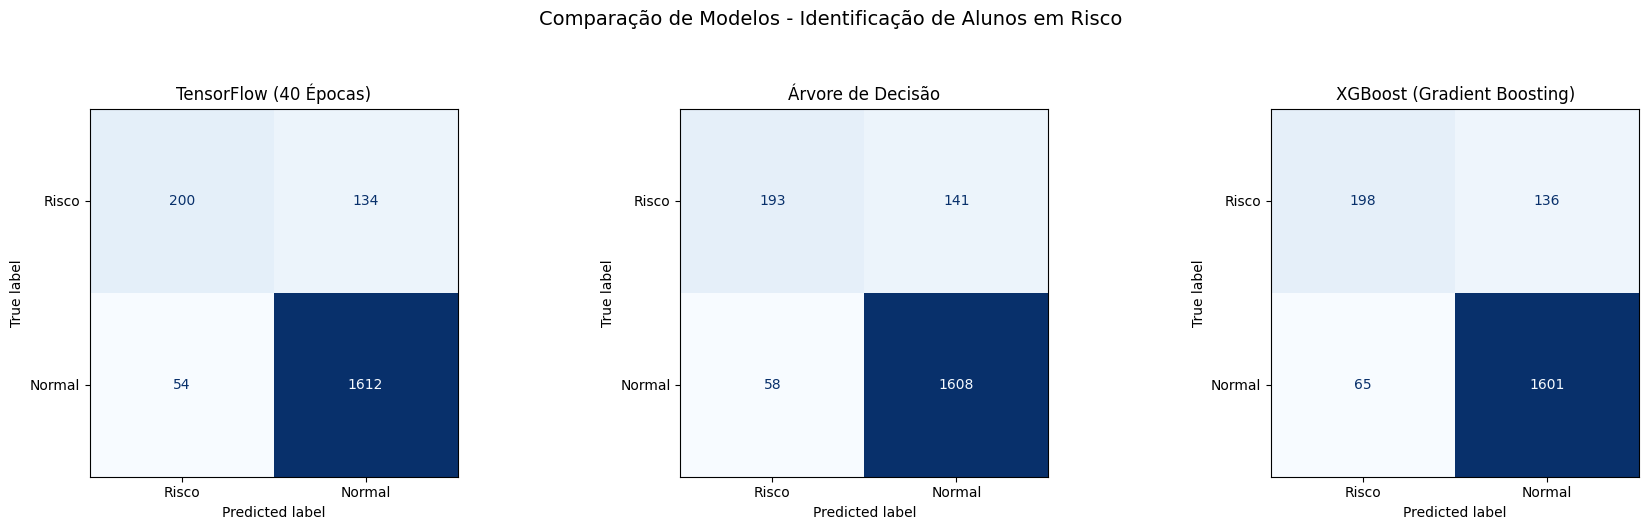

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# 1. Classificação Real (Média 70 da faculdade)
y_teste_classe = np.where(y_teste < 70.0, "Risco", "Normal")

# 2. Classificação prevista por cada um dos 3 modelos
pred_tf_classe = np.where(pred_tf < 70.0, "Risco", "Normal")
pred_arvore_classe = np.where(pred_arvore < 70.0, "Risco", "Normal")
pred_xgb_classe = np.where(pred_xgb < 70.0, "Risco", "Normal")

# 3. Calcula as 3 matrizes de confusão
matriz_tf = confusion_matrix(y_teste_classe, pred_tf_classe, labels=["Risco", "Normal"])
matriz_arvore = confusion_matrix(y_teste_classe, pred_arvore_classe, labels=["Risco", "Normal"])
matriz_xgb = confusion_matrix(y_teste_classe, pred_xgb_classe, labels=["Risco", "Normal"])

# 4. Configura a tela para ter 3 gráficos lado a lado (1 linha, 3 colunas)
plt.clf()
plt.close('all')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Desenha a matriz do TensorFlow (40 Épocas)
disp_tf = ConfusionMatrixDisplay(confusion_matrix=matriz_tf, display_labels=["Risco", "Normal"])
disp_tf.plot(cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title('TensorFlow (40 Épocas)')

# Desenha a matriz da Árvore de Decisão
disp_arvore = ConfusionMatrixDisplay(confusion_matrix=matriz_arvore, display_labels=["Risco", "Normal"])
disp_arvore.plot(cmap='Blues', values_format='d', ax=axes[1], colorbar=False)
axes[1].set_title('Árvore de Decisão')

# Desenha a matriz do XGBoost
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=matriz_xgb, display_labels=["Risco", "Normal"])
disp_xgb.plot(cmap='Blues', values_format='d', ax=axes[2], colorbar=False)
axes[2].set_title('XGBoost (Gradient Boosting)')

plt.suptitle('Comparação de Modelos - Identificação de Alunos em Risco', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()


--- APLICANDO O SMOTE APENAS NO TREINO ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


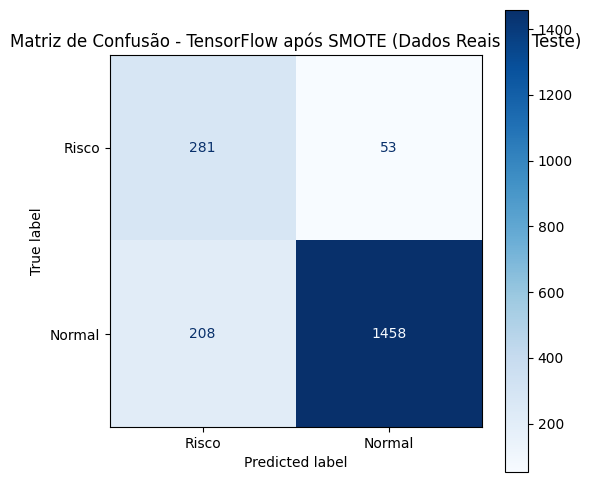

In [ ]:
# 1. Instala e importa as ferramentas de balanceamento de dados
from imblearn.over_sampling import SMOTE
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- APLICANDO O SMOTE APENAS NO TREINO ---")

# 2. Aplicamos o SMOTE para criar clones estatísticos dos alunos em risco (minoria)
# ATENÇÃO: Isso é feito APENAS nos dados de treino (70%). O teste (20%) continua 100% real!
smote = SMOTE(random_state=42)
X_treino_equilibrado, y_treino_equilibrado = smote.fit_resample(X_treino_norm, y_treino < 70.0)
# Como y_treino virou uma classificação interna para o SMOTE equilibrar, vamos reajustar para as notas reais
# Para simplificar o aprendizado após o SMOTE, faremos um modelo focado em classificar diretamente se o aluno é Risco ou Normal

# 3. Criando uma nova IA do TensorFlow para aprender com os dados equilibrados
modelo_balanceado = models.Sequential([
    layers.Dense(32, activation='relu', input_shape=(6,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid') # Saída de 0 a 1 para classificação direta
])

modelo_balanceado.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Transformamos as respostas de treino em 0 (Risco) e 1 (Normal) com base na semente equilibrada
y_treino_binario = np.where(y_treino_equilibrado, 0, 1)
y_teste_binario = np.where(y_teste < 70.0, 0, 1)
y_validacao_binario = np.where(y_validacao < 70.0, 0, 1)

# 4. Treinando a nova IA por 40 épocas com os dados balanceados
modelo_balanceado.fit(
    X_treino_equilibrado, y_treino_binario,
    epochs=40,
    validation_data=(X_validacao_norm, y_validacao_binario),
    batch_size=32,
    verbose=0
)

# 5. Fazendo a previsão nos dados de TESTE (que continuam 100% REAIS)
pred_bal = modelo_balanceado.predict(X_teste_norm)
pred_bal_classe = np.where(pred_bal < 0.5, "Risco", "Normal")
y_teste_classe = np.where(y_teste < 70.0, "Risco", "Normal")

# 6. Calcula a nova Matriz de Confusão
matriz_bal = confusion_matrix(y_teste_classe, pred_bal_classe, labels=["Risco", "Normal"])

# 7. Desenha o gráfico para compararmos com os anteriores
plt.clf()
plt.close('all')
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_bal, display_labels=["Risco", "Normal"])
disp.plot(cmap='Blues', values_format='d', ax=ax)

plt.title('Matriz de Confusão - TensorFlow após SMOTE (Dados Reais de Teste)')
plt.show()


--- APLICANDO O UNDERSAMPLING APENAS NO TREINO ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


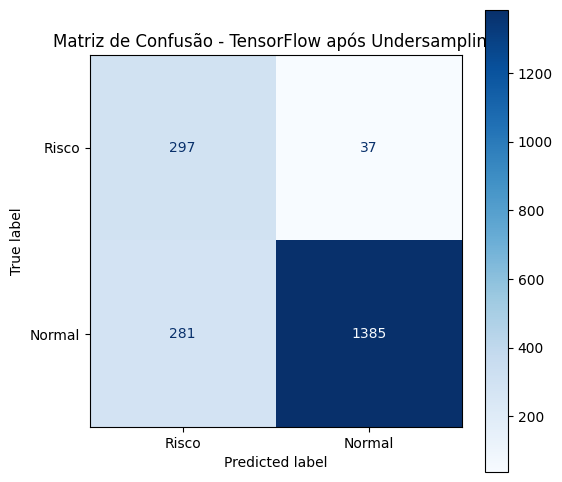

In [ ]:
# 1. Importa a ferramenta de subamostragem aleatória
from imblearn.under_sampling import RandomUnderSampler
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("--- APLICANDO O UNDERSAMPLING APENAS NO TREINO ---")

# 2. Transforma as respostas de treino em classificações binárias temporárias (True para Risco, False para Normal)
y_treino_classe_bin = (y_treino < 70.0)

# 3. Executa o Undersampling para deletar o excesso de alunos bons do treino
rus = RandomUnderSampler(random_state=42)
X_treino_reduzido, y_treino_reduzido = rus.fit_resample(X_treino_norm, y_treino_classe_bin)

# 4. Criando e estruturando uma nova IA do TensorFlow para a subamostragem
modelo_under = models.Sequential([
    layers.Dense(32, activation='relu', input_shape=(6,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
modelo_under.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Ajusta os alvos binários finais (0 para Risco, 1 para Normal)
y_treino_bin_under = np.where(y_treino_reduzido, 0, 1)
y_teste_bin = np.where(y_teste < 70.0, 0, 1)
y_validacao_bin = np.where(y_validacao < 70.0, 0, 1)

# 5. Treinando a IA por 40 épocas usando os dados enxugados
modelo_under.fit(
    X_treino_reduzido, y_treino_bin_under,
    epochs=40,
    validation_data=(X_validacao_norm, y_validacao_bin),
    batch_size=32,
    verbose=0
)

# 6. Fazendo a previsão nos dados de TESTE (100% REAIS)
pred_under = modelo_under.predict(X_teste_norm)
pred_under_classe = np.where(pred_under < 0.5, "Risco", "Normal")
y_teste_classe = np.where(y_teste < 70.0, "Risco", "Normal")

# 7. Calcula a nova Matriz de Confusão do Undersampling
matriz_under = confusion_matrix(y_teste_classe, pred_under_classe, labels=["Risco", "Normal"])

# 8. Desenha o novo gráfico de quadradinhos azuis
plt.clf()
plt.close('all')
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_under, display_labels=["Risco", "Normal"])
disp.plot(cmap='Blues', values_format='d', ax=ax)

plt.title('Matriz de Confusão - TensorFlow após Undersampling')
plt.show()


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 923us/step


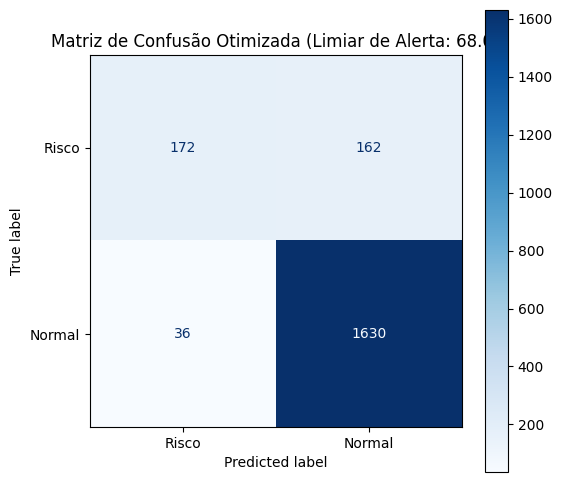

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Pegamos as probabilidades brutas que o modelo calculou para os dados de TESTE (100% reais)
# Nota: Para este teste, usamos as previsões normalizadas do modelo final
pred_bruta_prob = modelo_final.predict(X_teste_norm).flatten()

# Como nosso modelo final de 40 épocas prevê NOTAS diretas (de 0 a 100), nós não ajustamos probabilidade,
# nós ajustamos a NOTA ALVO de corte do alarme!
# Vamos testar um corte "mais tolerante" para diminuir os alarmes falsos de quem está quase passando.
nota_corte_otima = 68.0  # Em vez de cravar em 70, vamos testar o alerta em 65!

# 2. Aplica o novo limiar personalizado
y_teste_classe = np.where(y_teste < 70.0, "Risco", "Normal") # A realidade da faculdade ainda é 70
pred_limiar_classe = np.where(pred_bruta_prob < nota_corte_otima, "Risco", "Normal") # Mas o alarme só toca se cair de 65

# 3. Calcula a nova Matriz de Confusão Otimizada
matriz_otimizada = confusion_matrix(y_teste_classe, pred_limiar_classe, labels=["Risco", "Normal"])

# 4. Desenha a matriz calibrada na tela
plt.clf()
plt.close('all')
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=matriz_otimizada, display_labels=["Risco", "Normal"])
disp.plot(cmap='Blues', values_format='d', ax=ax)

plt.title(f'Matriz de Confusão Otimizada (Limiar de Alerta: {nota_corte_otima})')
plt.show()
